In [1]:
# Idea: try many theta values, compute the loss (cost) for each, plot loss vs theta.
# The lowest point of the curve is the best theta.
# Warm-up (linear):  y = 2x   -> theta = 1 (too small), theta = 2 (perfect), theta = 3 (too big)

In [2]:
import math
import matplotlib.pyplot as plt

x = [1,2,3]
y = [2,4,6]
print("x:", x)
print("y:", y)

x: [1, 2, 3]
y: [2, 4, 6]


In [3]:
theta = [0,1,2,3,4]
# 1/(2*m) * sum((y_pred - y)**2)
j_ = []
for i in theta:
    y_pred = [i*j for j in x]
    loss = 1/(2*len(x)) * sum([(y_pred[j] - y[j])**2 for j in range(len(y))])
    j_.append(loss)
    print(f"Theta: {i}, Loss: {loss}")

Theta: 0, Loss: 9.333333333333332
Theta: 1, Loss: 2.333333333333333
Theta: 2, Loss: 0.0
Theta: 3, Loss: 2.333333333333333
Theta: 4, Loss: 9.333333333333332


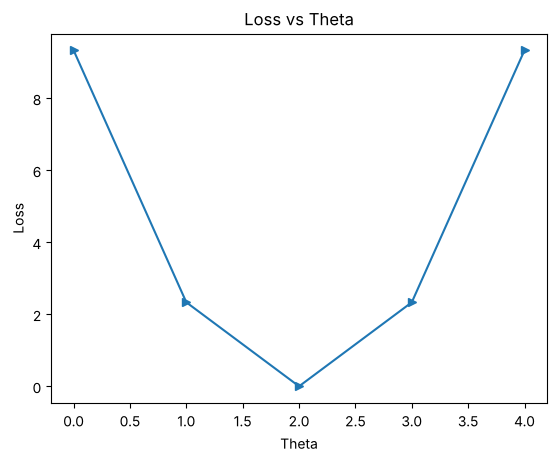

In [4]:
plt.plot(theta, j_, marker='>')
plt.xlabel("Theta"); plt.ylabel("Loss"); plt.title("Loss vs Theta")
plt.show()

## Now the same steps for logistic regression
Data: hours studied **per day** and pass (1) / fail (0) for 10 students.

Model: `p = 1 / (1 + e^-(theta0 + theta1*x))`  (probability of passing)

In [5]:
x = [1,2,3,4,5,6,7,8,9,10]
y = [0,0,0,0,1,0,1,1,1,1]
print("x:", x)
print("y:", y)

x: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
y: [0, 0, 0, 0, 1, 0, 1, 1, 1, 1]


In [6]:
def sigmoid(z):
    return 1/(1+math.exp(-z))

def predict(t0, t1, hours):
    return [sigmoid(t0 + t1*h) for h in hours]

# one student with 7 hours, theta0 = -5.5, theta1 = 1  -> z = 1.5
print(sigmoid(-5.5 + 1*7))

0.8175744761936437


### Loss for one student
- student passed (y = 1): `-log(p)`
- student failed (y = 0): `-log(1-p)`

One formula: `-(y*log(p) + (1-y)*log(1-p))`. The cost J is the **average** over all students.

In [7]:
def cost(t0, t1):
    p = predict(t0, t1, x)
    total = 0
    for i in range(len(y)):
        pi = min(max(p[i], 1e-12), 1-1e-12)
        total += -(y[i]*math.log(pi) + (1-y[i])*math.log(1-pi))
    return total/len(y)

print(cost(0, 0))      # every prediction is 0.5 -> ln 2

0.6931471805599453


## Step 1: try different theta1 values
To change only one number, fix theta0 and let only theta1 change. We assume the best theta0 is **-7.15**.
(Think of theta0 as already known, and we are searching for the best theta1.)

In [8]:
theta1 = [0, 0.25, 0.5, 1, 1.3, 2, 3, 5]
j_ = []
for t1 in theta1:
    t0 = -7.15
    loss = cost(t0, t1)
    j_.append(loss)
    print(f"Theta1: {t1}, Loss: {loss:.3f}")

Theta1: 0, Loss: 3.576
Theta1: 0.25, Loss: 2.604
Theta1: 0.5, Loss: 1.653
Theta1: 1, Loss: 0.393
Theta1: 1.3, Loss: 0.251
Theta1: 2, Loss: 0.644
Theta1: 3, Loss: 1.799
Theta1: 5, Loss: 4.657


Loss falls, reaches its lowest around theta1 = 1.3, then rises again. Theta1 = 0 is very bad because the model gives every student the same low chance (z = -7.15 for everyone).

## Step 2: plot Loss vs Theta1

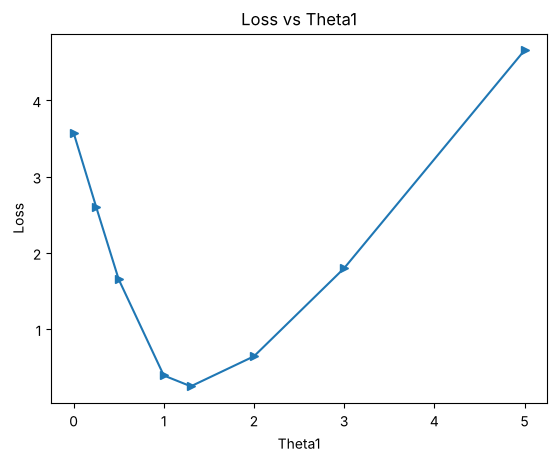

In [9]:
plt.plot(theta1, j_, marker='>')
plt.xlabel("Theta1"); plt.ylabel("Loss"); plt.title("Loss vs Theta1")
plt.show()

Smoother curve with many theta values:

best theta1 = 1.3  lowest loss = 0.251


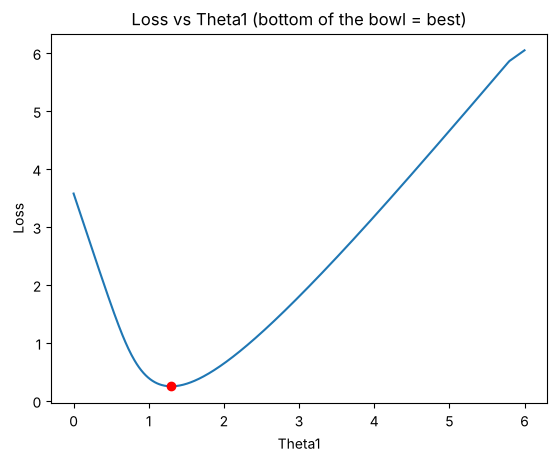

In [10]:
grid = [i/100 for i in range(0, 601)]
j_grid = [cost(-7.15, t) for t in grid]
best_i = j_grid.index(min(j_grid))
print("best theta1 =", grid[best_i], " lowest loss =", round(j_grid[best_i], 3))

plt.plot(grid, j_grid)
plt.scatter(grid[best_i], j_grid[best_i], color='red', zorder=5)
plt.xlabel("Theta1"); plt.ylabel("Loss"); plt.title("Loss vs Theta1 (bottom of the bowl = best)")
plt.show()

## Step 3: plot the curve for different thetas

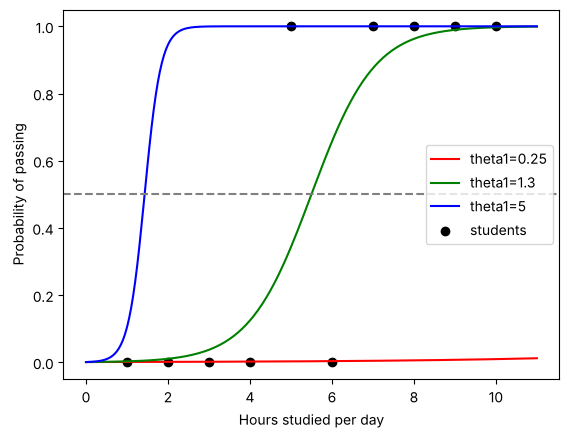

In [11]:
hh = [i/20 for i in range(0, 221)]   # 0 to 11 hours

plt.plot(hh, predict(-7.15, 0.25, hh), label="theta1=0.25", color='red')    # too small
plt.plot(hh, predict(-7.15, 1.3,  hh), label="theta1=1.3",  color='green')  # best
plt.plot(hh, predict(-7.15, 5,    hh), label="theta1=5",    color='blue')   # too big
plt.scatter(x, y, color='black', label="students")
plt.axhline(0.5, color='gray', linestyle='--')
plt.xlabel("Hours studied per day"); plt.ylabel("Probability of passing")
plt.legend(); plt.show()

In [12]:
for t1 in [0.25, 1.3, 5]:
    print(f"theta1 = {t1:4}  loss = {cost(-7.15, t1):.3f}")

theta1 = 0.25  loss = 2.604
theta1 =  1.3  loss = 0.251
theta1 =    5  loss = 4.657


- **theta1 = 0.25**: too small. Even 10 hours of study stays below 50%, so it predicts fail for everyone and the passers are badly wrong. High loss.
- **theta1 = 1.3**: crosses 50% at 5.5 hours and follows the pass/fail pattern. Lowest loss.
- **theta1 = 5**: too big. It crosses 50% at about 1.4 hours, so it says pass for almost everyone and the failers are badly wrong. High loss again.

## Step 4: now change both theta0 and theta1
Same idea with two thetas: try many pairs and shade each by its loss.

In [13]:
t0_vals = [-14 + i*0.2 for i in range(0, 81)]     # -14 to 2
t1_vals = [-0.5 + i*0.05 for i in range(0, 71)]   # -0.5 to 3
J = [[cost(a, b) for a in t0_vals] for b in t1_vals]

best = min((J[r][c], t0_vals[c], t1_vals[r]) for r in range(len(t1_vals)) for c in range(len(t0_vals)))
print("lowest loss =", round(best[0], 3), " at theta0 =", round(best[1], 2), " theta1 =", round(best[2], 2))

lowest loss = 0.251  at theta0 = -7.2  theta1 = 1.3


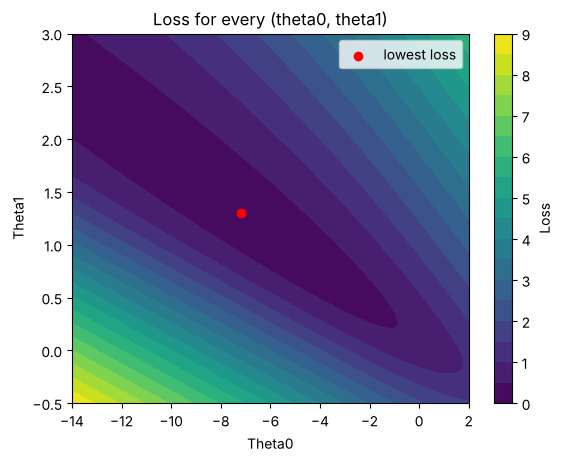

In [14]:
plt.contourf(t0_vals, t1_vals, J, levels=20)
plt.colorbar(label="Loss")
plt.scatter(best[1], best[2], color='red', label='lowest loss')
plt.xlabel("Theta0"); plt.ylabel("Theta1"); plt.title("Loss for every (theta0, theta1)")
plt.legend(); plt.show()

## Step 5: why log loss and not squared error?
Same theta1 sweep, but measure with squared error on the sigmoid output.

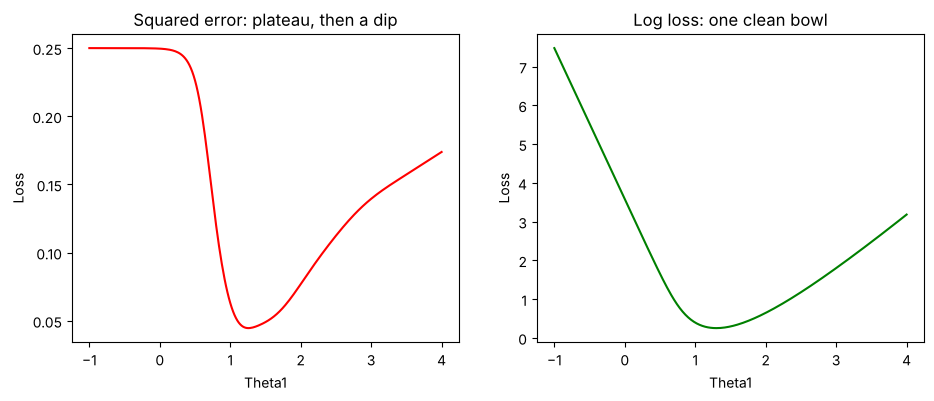

In [15]:
def mse_cost(t0, t1):
    p = predict(t0, t1, x)
    return sum([(p[i]-y[i])**2 for i in range(len(y))])/(2*len(y))

grid2 = [-1 + i*0.02 for i in range(0, 251)]
mse_j = [mse_cost(-7.15, t) for t in grid2]
log_j = [cost(-7.15, t) for t in grid2]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(grid2, mse_j, color='red');   ax[0].set_title("Squared error: plateau, then a dip")
ax[1].plot(grid2, log_j, color='green'); ax[1].set_title("Log loss: one clean bowl")
for a in ax: a.set_xlabel("Theta1"); a.set_ylabel("Loss")
plt.show()

On the flat part the slope is almost zero, so gradient descent barely moves. Log loss is a clean bowl, so we use it.

## Regularization: a penalty pulls a large theta back
Take a case where the pass/fail pattern is perfectly clean: everyone with 6 or more hours passed, everyone below failed. Then the loss keeps falling as theta1 grows (a steeper curve is always "more sure"), so without a penalty theta1 just runs off to a huge value.

(Here we keep the boundary at 5.5 hours, `theta0 = -5.5 * theta1`, because that boundary separates the clean data perfectly.) A penalty makes large theta1 costly. New cost = log loss + `lambda * theta1^2`

In [16]:
y_s = [0,0,0,0,0,1,1,1,1,1]

def cost_s(t1, lam=0):
    t0 = -5.5*t1     # boundary kept at 5.5 hours, which separates this clean data perfectly
    total = 0
    for i in range(len(y_s)):
        pi = sigmoid(t0 + t1*x[i])
        pi = min(max(pi, 1e-12), 1-1e-12)
        total += -(y_s[i]*math.log(pi) + (1-y_s[i])*math.log(1-pi))
    return total/len(y_s) + lam*t1**2

grid3 = [i/20 for i in range(0, 201)]   # theta1 from 0 to 10
for lam in [0, 0.001, 0.01, 0.05]:
    j_l = [cost_s(t, lam) for t in grid3]
    k = j_l.index(min(j_l))
    print(f"lambda = {lam:5}  best theta1 = {grid3[k]:.2f}  cost J = {j_l[k]:.3f}")

lambda =     0  best theta1 = 10.00  cost J = 0.001
lambda = 0.001  best theta1 = 4.65  cost J = 0.040
lambda =  0.01  best theta1 = 2.10  cost J = 0.114
lambda =  0.05  best theta1 = 1.20  cost J = 0.204


With lambda = 0 the best theta1 is the edge of the grid (it wants to keep growing). As lambda grows, the best theta1 comes back to a smaller, safer value.

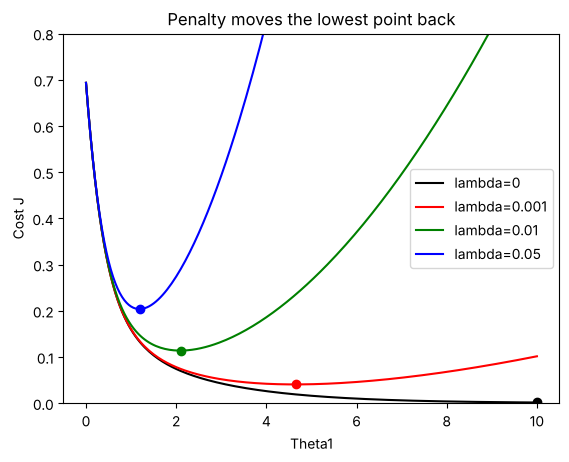

In [17]:
for lam, c in [(0, 'black'), (0.001, 'red'), (0.01, 'green'), (0.05, 'blue')]:
    j_l = [cost_s(t, lam) for t in grid3]
    k = j_l.index(min(j_l))
    plt.plot(grid3, j_l, color=c, label=f"lambda={lam}")
    plt.scatter(grid3[k], j_l[k], color=c, zorder=5)
plt.ylim(0, 0.8)
plt.xlabel("Theta1"); plt.ylabel("Cost J"); plt.title("Penalty moves the lowest point back")
plt.legend(); plt.show()

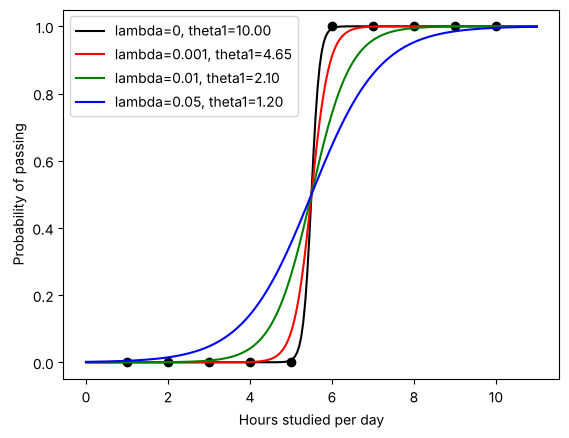

In [18]:
hh = [i/20 for i in range(0, 221)]
for lam, c in [(0, 'black'), (0.001, 'red'), (0.01, 'green'), (0.05, 'blue')]:
    j_l = [cost_s(t, lam) for t in grid3]
    t1 = grid3[j_l.index(min(j_l))]
    plt.plot(hh, predict(-5.5*t1, t1, hh), color=c, label=f"lambda={lam}, theta1={t1:.2f}")
plt.scatter(x, y_s, color='black')
plt.xlabel("Hours studied per day"); plt.ylabel("Probability of passing")
plt.legend(); plt.show()